# Eksperimen MLP dengan Backpropagation

**Proyek akhir JST — konfigurasi, pelatihan, checkpoint, dan evaluasi validation**

Tujuan notebook: membangun baseline, membandingkan input/hidden/aktivasi/loss/epoch, menilai regularisasi serta kestabilan seed, dan menyimpan bukti eksperimen.

Semua model prediksi berupa **Multi Layer Perceptron feedforward**, dilatih melalui backpropagation menggunakan PyTorch. Output satu neuron linear untuk SOH terstandar. **Test tidak dimuat atau dievaluasi.**

Konfigurasi telah ditetapkan dalam `configs/mlp_study.json`. Run selesai dengan fingerprint data/kode/config yang cocok dipakai ulang; pada komputer baru tanpa checkpoint lokal, notebook akan melatih ulang. Angka hasil yang ditampilkan berasal dari run nyata, bukan angka contoh.

## 1. Lingkungan dan protokol yang dikunci

- Train: 34.929 observasi; validation: 7.499 observasi; baterai tidak tumpang tindih.
- Pipeline preprocessing sudah fit hanya pada train. Tidak melatih ulang scaler dari validation.
- Seleksi: MAE validation pada SOH asli, bukan angka loss berbeda skala.
- CPU dua thread, batch 256 tetap, Adam learning rate 0,001, maksimum 200 epoch.
- Pencarian seed 42, konfirmasi seed 42/123/2026.
- Tidak menambahkan feature engineering domain pada tahap ini; tiga resep preprocessing dibandingkan lebih dahulu.

Batch 256 dipilih demi training CPU yang praktis, menggantikan rekomendasi awal 32 pada panduan. Kebijakan ini sama pada semua pembanding dan tidak dituning berdasarkan skor.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Image
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/mlp_experiments.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Buka dari root proyek atau folder notebooks.')
if str(ROOT) not in sys.path:
    sys.path.insert(0,str(ROOT))
from src.mlp_experiments import configure_runtime, run_study, load_training_data, load_checkpoint, predict_scaled, original_scale, regression_metrics
from src.experiment_reporting import build_report, read_results
pd.set_option('display.max_columns',16)
pd.set_option('display.max_colwidth',80)
pd.set_option('display.precision',5)
settings = json.loads((ROOT/'configs/mlp_study.json').read_text(encoding='utf-8'))
configure_runtime(42,settings['cpu_threads'])
print('PyTorch:',torch.__version__,'device:',settings['device'],'threads:',settings['cpu_threads'])
display(pd.Series(settings['baseline'],name='baseline_config').to_frame())

PyTorch: 2.11.0+cpu device: cpu threads: 2


,baseline_config
recipe,baseline_standard
hidden_layers,"[64, 32]"
activation,relu
loss,mse
huber_delta,1.0
learning_rate,0.001
batch_size,256
max_epochs,200
early_stopping,True
patience,15


## 2. Input dan skala target

Loader eksperimen hanya meminta train dan validation. Target pada array `y_scaled` untuk optimasi; `y_original` untuk MAE/RMSE/R². Identitas fitted preprocessing diperiksa agar array/model tidak tercampur.

Baseline memakai 67 input, hasil encoding/indikator dari 21 fitur mentah. Compact memakai 63. Ini bukan jumlah observasi atau timesteps.

In [2]:
baseline_data = load_training_data('baseline_standard',ROOT)
rows=[]
for split in ['train','validation']:
    data=baseline_data[split]
    rows.append({'split':split,'rows':len(data['X']),'batteries':len(set(data['battery_id'])),'input_features':data['X'].shape[1],'dtype':str(data['X'].dtype)})
display(pd.DataFrame(rows))
assert set(baseline_data['train']['battery_id']).isdisjoint(baseline_data['validation']['battery_id'])
assert baseline_data['train']['X'].shape[1]==67
assert np.isfinite(baseline_data['train']['X']).all()
print('Tidak ada permintaan split test.')

,split,rows,batteries,input_features,dtype
0,train,34929,1820,67,float32
1,validation,7499,390,67,float32


Tidak ada permintaan split test.


## 3. Forward, loss, backward, dan update bobot

Untuk setiap layer: `z = W a + b`, lalu aktivasi hidden; output akhir linear. Satu mini-batch menjalankan:

```python
optimizer.zero_grad(set_to_none=True)
predicted = model(X_batch)           # forward, shape (N,)
loss = criterion(predicted, y_batch)
loss.backward()                      # backpropagation / chain rule
optimizer.step()                     # update bobot oleh Adam
```

PyTorch menghitung gradien melalui autograd. Ini implementasi MLP dengan backpropagation; bukan ELM atau pelatihan JST lain. Semua aktivasi memakai Xavier uniform gain=1 dan bias nol sebagai kebijakan inisialisasi bersama. MSE/MAE/Huber dioptimalkan pada target terstandar.

In [3]:
# Verifikasi kecil terhadap contoh manual di CONTEXT.md; bukan data baterai.
w1=torch.tensor(.5,requires_grad=True);b1=torch.tensor(0.,requires_grad=True)
w2=torch.tensor(.4,requires_grad=True);b2=torch.tensor(0.,requires_grad=True)
h=torch.relu(w1*2+b1)
pred=w2*h+b2
manual_loss=.5*(pred-1).square()
manual_loss.backward()
gradients=pd.DataFrame({'parameter':['w1','b1','w2','b2'],
                        'autograd':[w1.grad.item(),b1.grad.item(),w2.grad.item(),b2.grad.item()],
                        'manual_expected':[-.48,-.24,-.6,-.6]})
display(gradients)
np.testing.assert_allclose(gradients.autograd,gradients.manual_expected,atol=1e-6)
print('PASS: chain rule manual sesuai backpropagation autograd.')

,parameter,autograd,manual_expected
0,w1,-0.48,-0.48
1,b1,-0.24,-0.24
2,w2,-0.60,-0.60
3,b2,-0.60,-0.60


PASS: chain rule manual sesuai backpropagation autograd.


## 4. Jalankan study atau pakai ulang run selesai yang cocok

Tahap: baseline → preprocessing → hidden → aktivasi → loss → regularisasi → diagnosis epoch tetap → konfirmasi seed. Pemenang tiap tahap dipilih dengan MAE validation seed 42. Ini pencarian bertahap, bukan full factorial.

Training membutuhkan checkpoint lokal dan array preprocessing. Rerun dengan cache yang cocok tidak mengubah skor dan tidak membuat run identik berulang. Study pertama benar-benar melatih model; cache hanya memuat run lengkap dengan fingerprint cocok. Jika dari clone baru, jalankan sel ini dengan timeout yang cukup.

In [4]:
study = run_study(ROOT)
report = build_report(ROOT)
output,study,runs,tables,summaries,histories = read_results(ROOT)
def show(name,width=1100):
    display(Image(filename=str(output/name),width=width))
print('Run unik selesai:',study['unique_training_runs'])
print('Total waktu training run unik (detik):',round(study['total_training_seconds'],1))
assert study['test_loaded'] is False
assert study['unique_training_runs']==len(runs)
assert runs.run_id.is_unique
print('Baseline:',study['baseline_run_id'],'Kandidat sementara:',study['candidate_run_id'])

SELECT preprocessing: run_710346c78efb validation MAE=1.0451

SELECT hidden_layers: run_f76968c3adcb validation MAE=1.0394


SELECT activation: run_6ad052ad28d7 validation MAE=0.9920


SELECT loss: run_001bb572bf8f validation MAE=0.9752


SELECT regularization: run_417429878fc7 validation MAE=0.9726


Run unik selesai: 17
Total waktu training run unik (detik): 125.6
Baseline: run_83aa5197bac6 Kandidat sementara: run_417429878fc7


## 5. Baseline: jaringan benar-benar belajar?

Lihat loss sebelum dan sesudah update, MAE train–validation, gradien batch pertama, dan perubahan bobot. Kurva end-of-epoch memakai mode eval tanpa dropout, sehingga membandingkan bobot serta prosedur evaluasi yang sama.

`batch_objective_scaled` menyimpan rata-rata loss saat mini-batch memperbarui bobot; itu berbeda dari full-train evaluation loss. Jangan membandingkan kedua angka tersebut seolah-olah dihitung pada bobot sama.

,model,input,parameters,epoch_best,epoch_actual,train_mae_pp,validation_mae_pp,validation_rmse_pp,validation_r2
0,baseline,67,6465,22,37,0.88613,1.04954,1.53503,0.95218
1,candidate_seed42,67,2209,123,126,0.92277,0.97258,1.49731,0.95450


,batch_pertama_baseline
batch_loss_scaled,1.30784
gradient_l2_norm,2.73380
first_layer_gradient_l2_norm,1.78389
first_layer_max_weight_change,0.00100


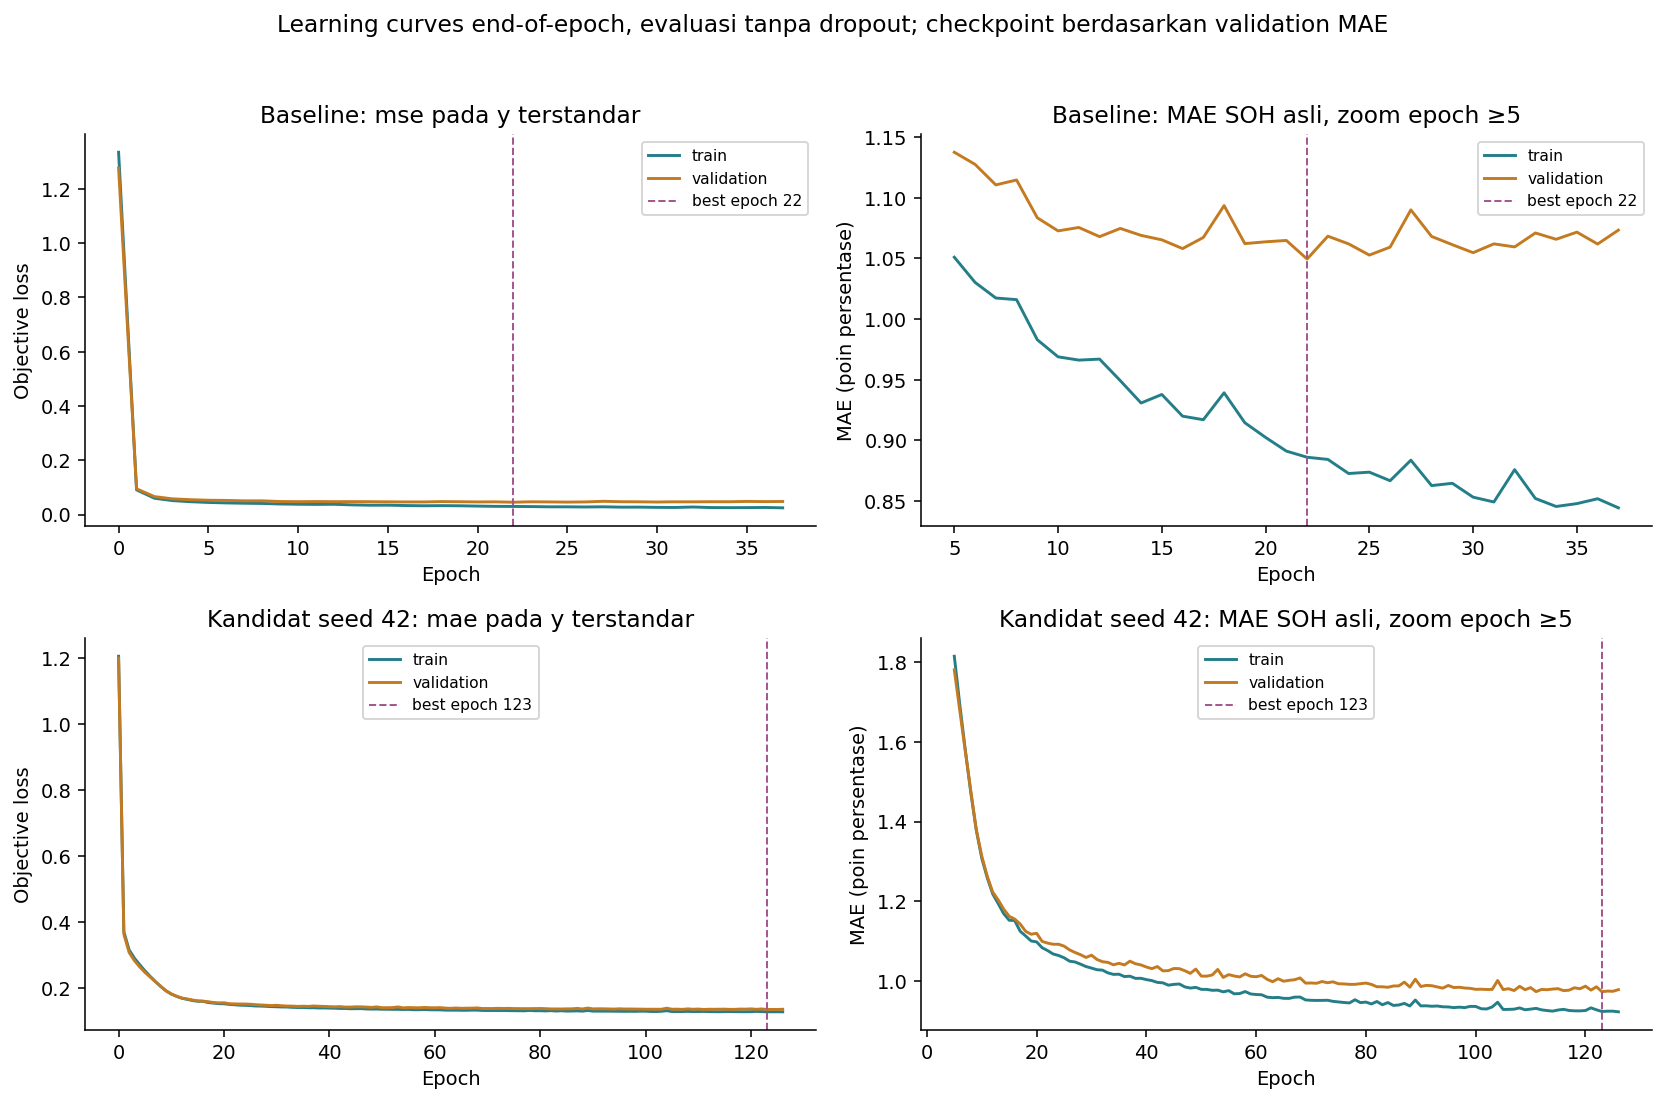

In [5]:
baseline = summaries[study['baseline_run_id']]
candidate = summaries[study['candidate_run_id']]
comparison=[]
for label,run in [('baseline',baseline),('candidate_seed42',candidate)]:
    comparison.append({'model':label,'input':run['input_features'],'parameters':run['parameters'],
                       'epoch_best':run['best_epoch'],'epoch_actual':run['epochs_actual'],
                       'train_mae_pp':run['train']['mae'],'validation_mae_pp':run['validation']['mae'],
                       'validation_rmse_pp':run['validation']['rmse'],'validation_r2':run['validation']['r2']})
display(pd.DataFrame(comparison))
display(pd.Series(baseline['first_update'],name='batch_pertama_baseline').to_frame())
assert baseline['first_update']['gradient_l2_norm']>0
assert baseline['first_update']['first_layer_max_weight_change']>0
show('01_learning_curves.png')

**Temuan baseline:** MAE train sekitar 0,886 dan validation 1,050 poin SOH. Checkpoint minimum epoch 22, sedangkan training berhenti epoch 37. Train loss yang turun dan bobot yang berubah menunjukkan proses belajar berjalan. Gap train–validation menunjukkan tetap ada generalization gap; bukan bukti model bebas overfitting.

Panel objective menampilkan sejak epoch 0; panel MAE diperbesar mulai epoch 5 agar generalization gap terlihat. Epoch 0 hanya menunjukkan jaringan sebelum update, tidak ikut dipilih sebagai checkpoint. Kurva kandidat menggunakan loss yang sesuai konfigurasinya sendiri; angka objective MSE baseline tidak dibandingkan langsung dengan objective MAE kandidat.

## 6. Checkpoint: best berbeda dari last

- **best.pt:** MAE validation terendah persis pada epoch training yang dijalankan.
- **last.pt:** bobot pada epoch terakhir sebelum berhenti.
- Patience 15 direset untuk perbaikan terhadap referensi patience minimal 0,001 poin SOH. Perbaikan lebih kecil tetap dapat memperbarui checkpoint best.

Checkpoint menyertakan konfigurasi, nama fitur, fingerprint data, epoch, optimizer state, dan RNG torch/shuffle. Runner belum menawarkan resume tengah-epoch: run terputus dapat diulang dari awal. Checkpoint lokal tidak dikomit; konfigurasi/history/summary dapat dibuat ulang.

In [6]:
model,checkpoint = load_checkpoint(ROOT/baseline['checkpoint_best'],baseline_data)
pred_scaled = predict_scaled(model,torch.from_numpy(baseline_data['validation']['X']))
pred_soh = original_scale(pred_scaled,baseline_data['bundle'])
recomputed = regression_metrics(baseline_data['validation']['y_original'],pred_soh,baseline_data['validation']['battery_id'])
assert np.isclose(recomputed['mae'],baseline['validation']['mae'],atol=1e-9)
history = histories[baseline['run_id']]
trained = history.loc[history.epoch.gt(0)]
assert checkpoint['epoch']==int(trained.loc[trained.validation_mae_pp.idxmin(),'epoch'])
assert not model.training
print('PASS: reload best checkpoint menghasilkan MAE yang sama dan epoch minimum history.')
print(model)

PASS: reload best checkpoint menghasilkan MAE yang sama dan epoch minimum history.
MLP(
  (network): Sequential(
    (0): Linear(in_features=67, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 7. Perbandingan konfigurasi dan keputusan tiap tahap

Semua tahap menggunakan batch, learning rate, split, seed pencarian, dan aturan stopping yang sama. Jumlah epoch aktual dapat berbeda karena early stopping dan dicatat. Kandidat tahap sebelumnya diteruskan, sehingga setiap baris harus dibaca dalam konteks tahapnya.

,stage,run_id,selected,validation_mae_pp,train_mae_pp,recipe,hidden_layers,activation,loss,weight_decay,dropout
0,preprocessing,run_83aa5197bac6,False,1.04954,0.88613,baseline_standard,64-32,relu,mse,0.0000,0.0
1,preprocessing,run_710346c78efb,True,1.04512,0.86427,log_sensor_caps,64-32,relu,mse,0.0000,0.0
2,preprocessing,run_c10d3e442614,False,1.07253,0.85006,compact_log_sensor_caps,64-32,relu,mse,0.0000,0.0
3,hidden_layers,run_f76968c3adcb,True,1.03938,0.94654,log_sensor_caps,32,relu,mse,0.0000,0.0
4,hidden_layers,run_7e756de0e2ab,False,1.04232,0.87354,log_sensor_caps,64,relu,mse,0.0000,0.0
5,hidden_layers,run_710346c78efb,False,1.04512,0.86427,log_sensor_caps,64-32,relu,mse,0.0000,0.0
6,hidden_layers,run_0ec862f4da27,False,1.06409,0.74119,log_sensor_caps,128-64-32,relu,mse,0.0000,0.0
7,activation,run_f76968c3adcb,False,1.03938,0.94654,log_sensor_caps,32,relu,mse,0.0000,0.0
8,activation,run_561c2914606b,False,1.03011,0.95909,log_sensor_caps,32,tanh,mse,0.0000,0.0
9,activation,run_6ad052ad28d7,True,0.99199,0.94073,log_sensor_caps,32,sigmoid,mse,0.0000,0.0


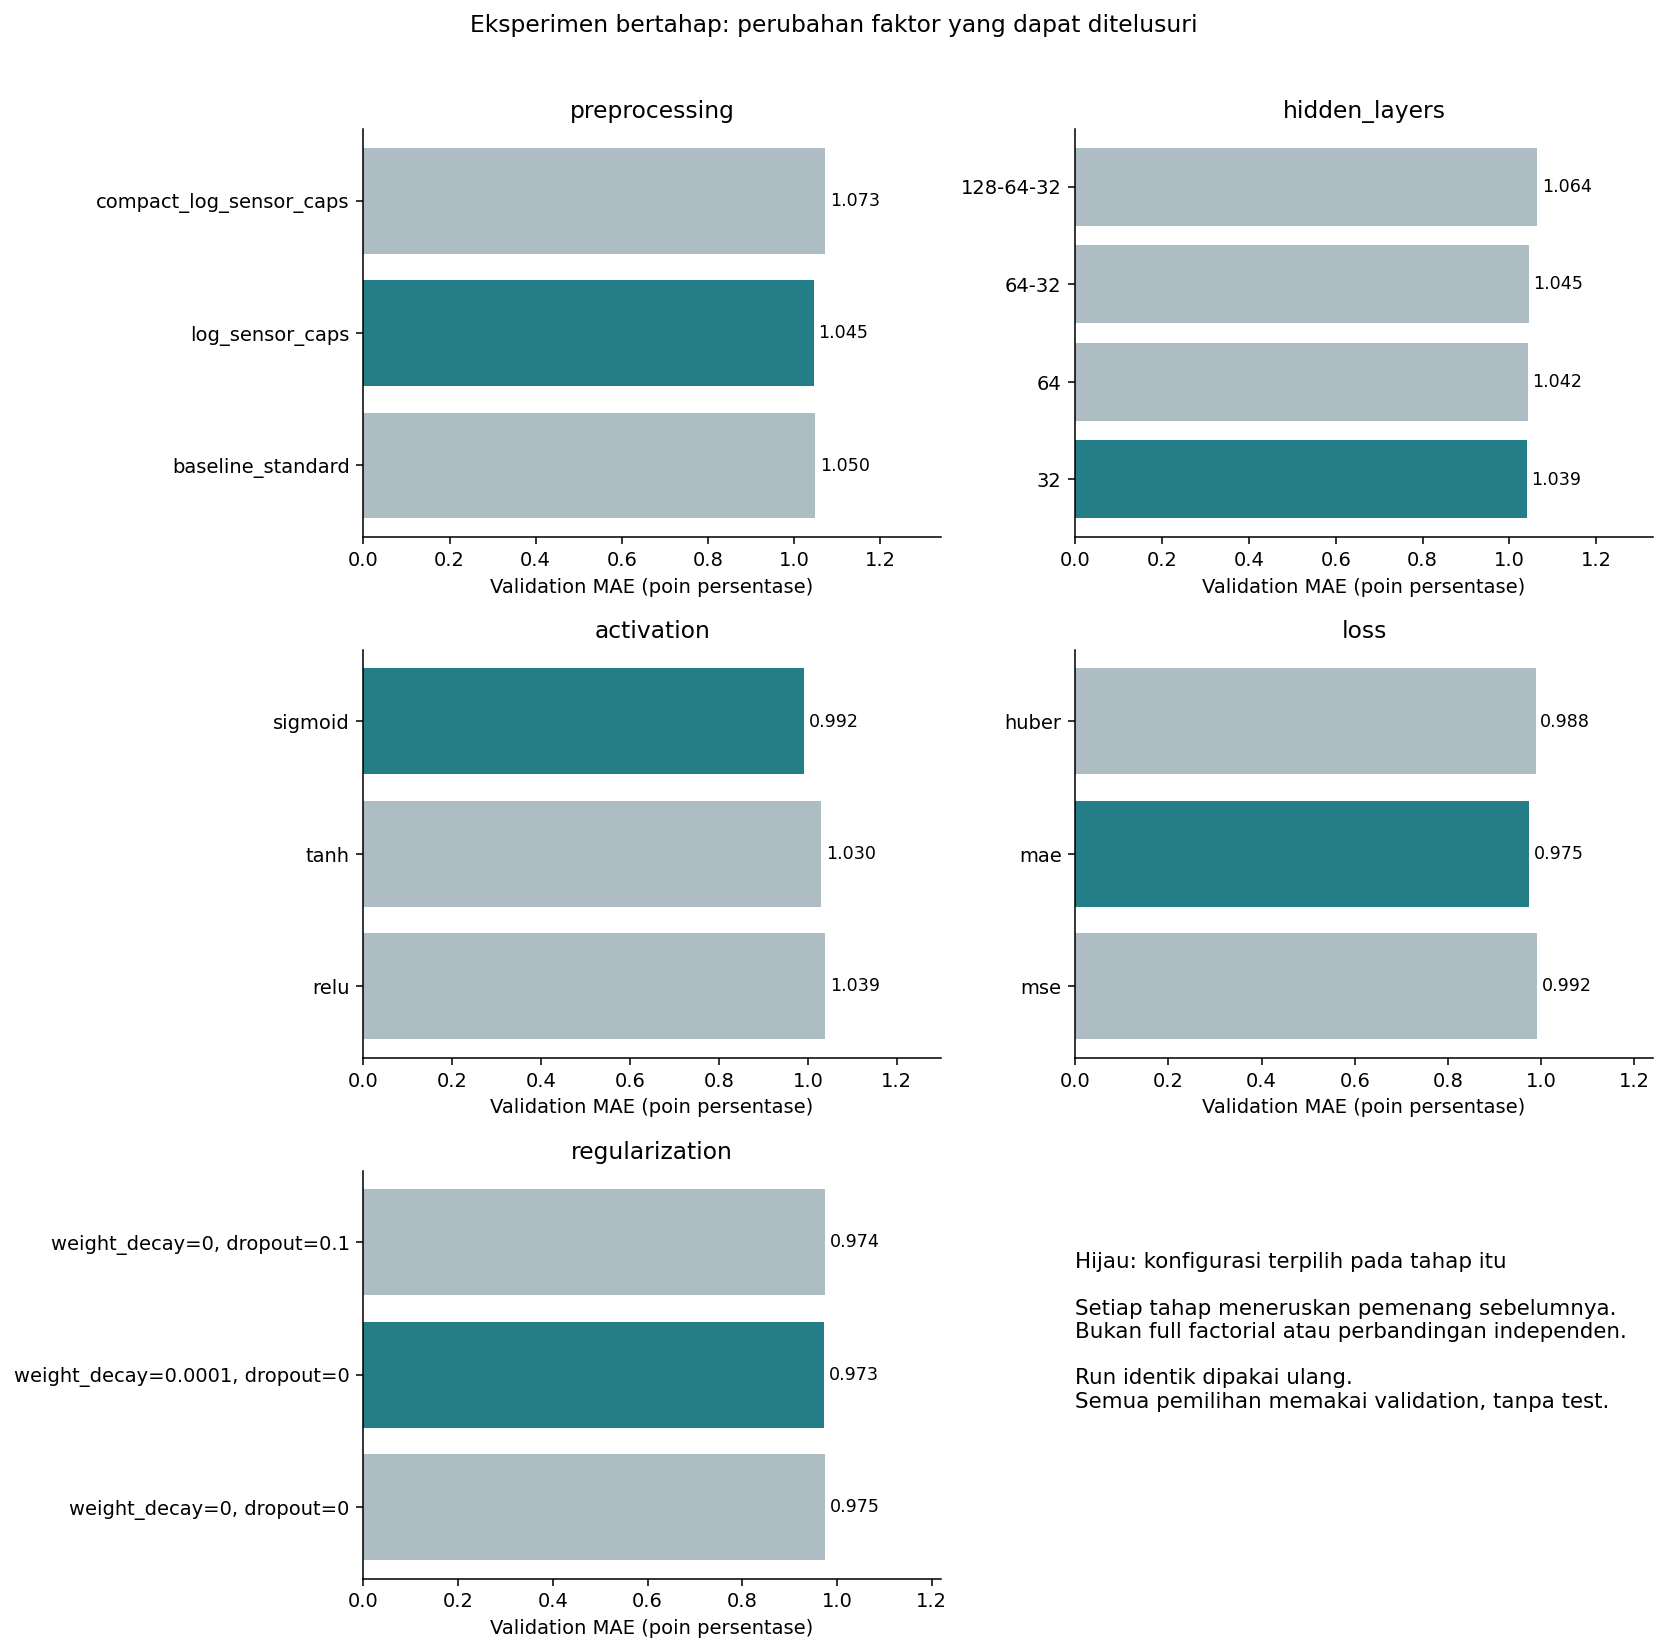

In [7]:
display(tables['stage_comparisons'])
show('02_stage_comparisons.png')

**Cara membaca hasil:** perubahan log/cap memberi selisih kecil pada baseline sehingga belum layak dianggap unggul universal. Hidden yang lebih dalam tidak otomatis menang; pada pencarian ini [32] menjadi kandidat sebelum perbandingan aktivasi. Sigmoid lalu MAE dan regularisasi ringan memberi MAE validation lebih rendah pada konfigurasi tersebut.

Kesimpulan “sigmoid selalu lebih baik” atau “satu hidden selalu cukup” tidak sah. Inisialisasi, dataset, loss, early stopping, dan pencarian bertahap membatasi kesimpulan. MSE/MAE/Huber dinilai dengan metrik yang sama pada SOH asli, bukan besarnya loss masing-masing.

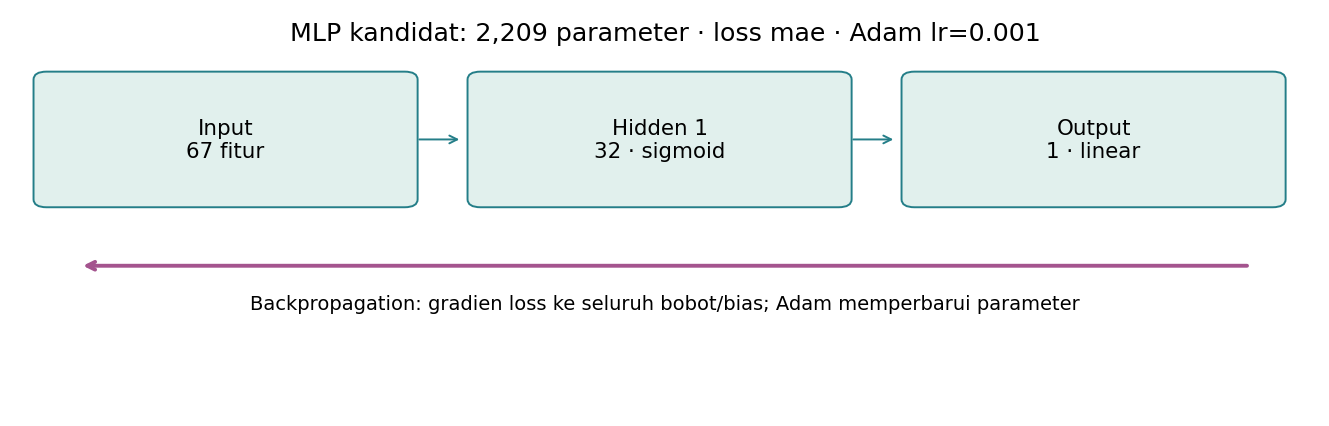

,candidate_config
recipe,log_sensor_caps
hidden_layers,[32]
activation,sigmoid
loss,mae
huber_delta,1.0
learning_rate,0.001
batch_size,256
max_epochs,200
early_stopping,True
patience,15


Jumlah parameter: 2209


In [8]:
show('03_candidate_architecture.png')
display(pd.Series(candidate['config'],name='candidate_config').to_frame())
print('Jumlah parameter:',candidate['parameters'])
assert candidate['input_features']==67
assert candidate['parameters']==2209

**Kandidat sementara:** resep log_sensor_caps, input 67, hidden [32], sigmoid, output linear, loss MAE, Adam learning rate 0,001, weight_decay 1e-4, dropout 0. Jaringan memiliki 2.209 parameter, dibanding 6.465 pada baseline. Konfigurasi ini dipilih menggunakan validation dan belum diuji pada test.

Huber delta=1 dinyatakan pada y_scaled (sekitar 7,193 poin SOH), bukan delta 1 poin SOH. Weight decay diterapkan optimizer; kurva objective data tidak menjumlahkan penalti optimizer secara eksplisit.

## 8. Epoch tetap: endpoint bukan checkpoint terbaik

Untuk mengisolasi anggaran epoch, satu model kandidat seed 42 dilatih sampai 200 epoch **tanpa early stopping**. Bobot epoch 50, 100, dan 200 disimpan. Karena berasal dari trajectory yang sama, ini bukan tiga run independen.

Tabel berikut adalah metrik **bobot pada akhir epoch tersebut**, bukan minimum validation pada prefix training. Run diagnostik tidak dipromosikan ke kandidat pencarian meskipun suatu best checkpoint-nya terlihat lebih rendah.

,epoch,train_mae,validation_mae,validation_rmse,validation_r2
0,50,0.97844,1.01176,1.56525,0.95028
1,100,0.93547,0.97850,1.50844,0.95382
2,200,0.90762,0.98090,1.49904,0.95440


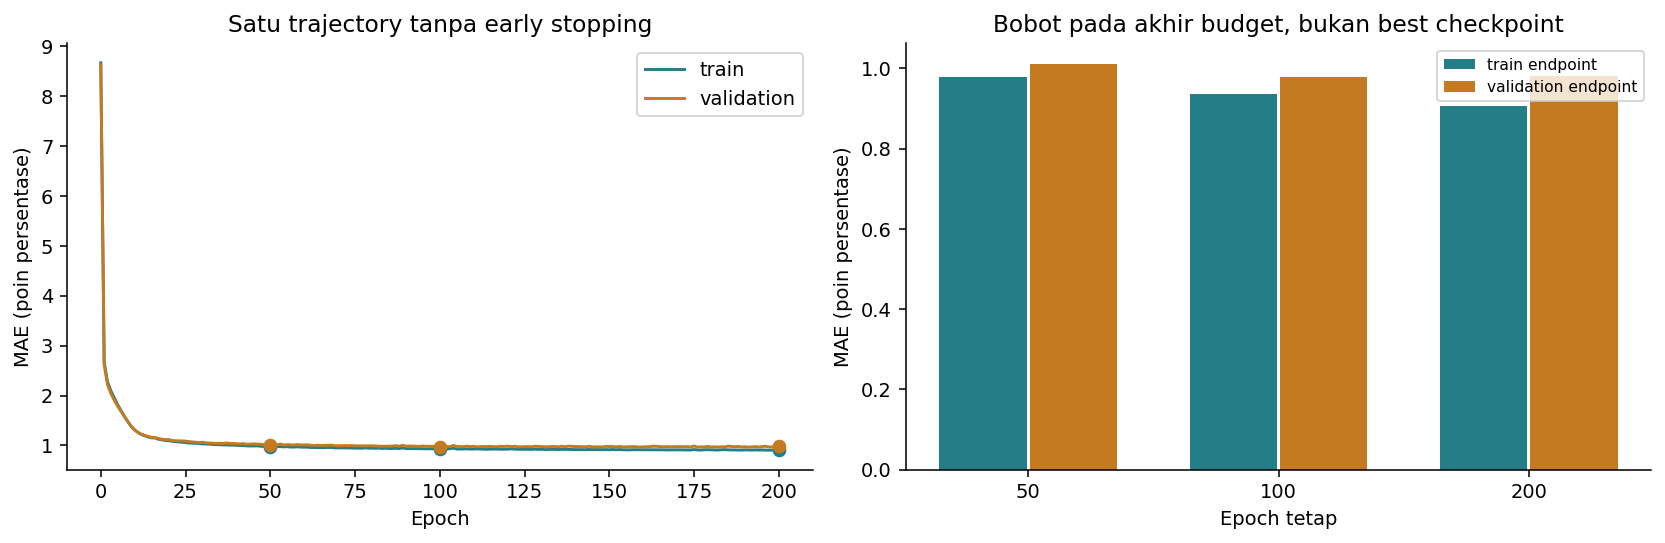

Best checkpoint trajectory diagnostik: 191 0.96687


In [9]:
display(tables['epoch_budget_comparison'][['epoch','train_mae','validation_mae','validation_rmse','validation_r2']])
show('04_epoch_budget.png')
fixed = summaries[study['fixed_epoch_run_id']]
print('Best checkpoint trajectory diagnostik:',fixed['best_epoch'],round(fixed['validation']['mae'],5))
assert fixed['config']['early_stopping'] is False and fixed['epochs_actual']==200
assert tables['epoch_budget_comparison'].epoch.tolist()==[50,100,200]

**Temuan:** endpoint validation MAE sekitar 1,012 (50 epoch), 0,979 (100), dan 0,981 (200), sementara train terus membaik. Memperpanjang training tidak otomatis memperbaiki validation.

Trajectory diagnostik juga menemukan best epoch 191 dengan MAE sekitar 0,967. Itu berbeda dari endpoint 200 dan lebih lambat daripada early stopping kandidat awal. Hal ini menunjukkan patience adalah heuristik yang bisa melewatkan perbaikan terlambat. Hasil tersebut tetap dilaporkan, tanpa mengubah diam-diam protokol seleksi kandidat.

## 9. Konfirmasi tiga seed: apakah hasilnya stabil?

Konfigurasi kandidat dipilih pada seed 42 sebelum konfirmasi. Baseline dan kandidat dijalankan pada 42, 123, dan 2026. Split tetap sama; seed mengubah inisialisasi dan urutan mini-batch. Semua seed dilaporkan, bukan hanya hasil terbaik.

,group,seed,run_id,validation_mae_pp,validation_rmse_pp,validation_r2,train_mae_pp,best_epoch
0,baseline,42,run_83aa5197bac6,1.04954,1.53503,0.95218,0.88613,22
1,baseline,123,run_567cd20b04c3,1.04564,1.52602,0.95274,0.88048,23
2,baseline,2026,run_e8aecfd9751c,1.04523,1.53365,0.95227,0.86927,22
3,candidate,42,run_417429878fc7,0.97258,1.49731,0.95450,0.92277,123
4,candidate,123,run_312fdc17ada1,0.97610,1.49996,0.95434,0.92853,116
5,candidate,2026,run_73d0ae8e6140,0.97706,1.50805,0.95385,0.93225,100


,group,n_seeds,validation_mae_mean,validation_mae_std,validation_rmse_mean,validation_r2_mean
0,baseline,3,1.04680,0.00238,1.53157,0.95240
1,candidate,3,0.97525,0.00236,1.50177,0.95423


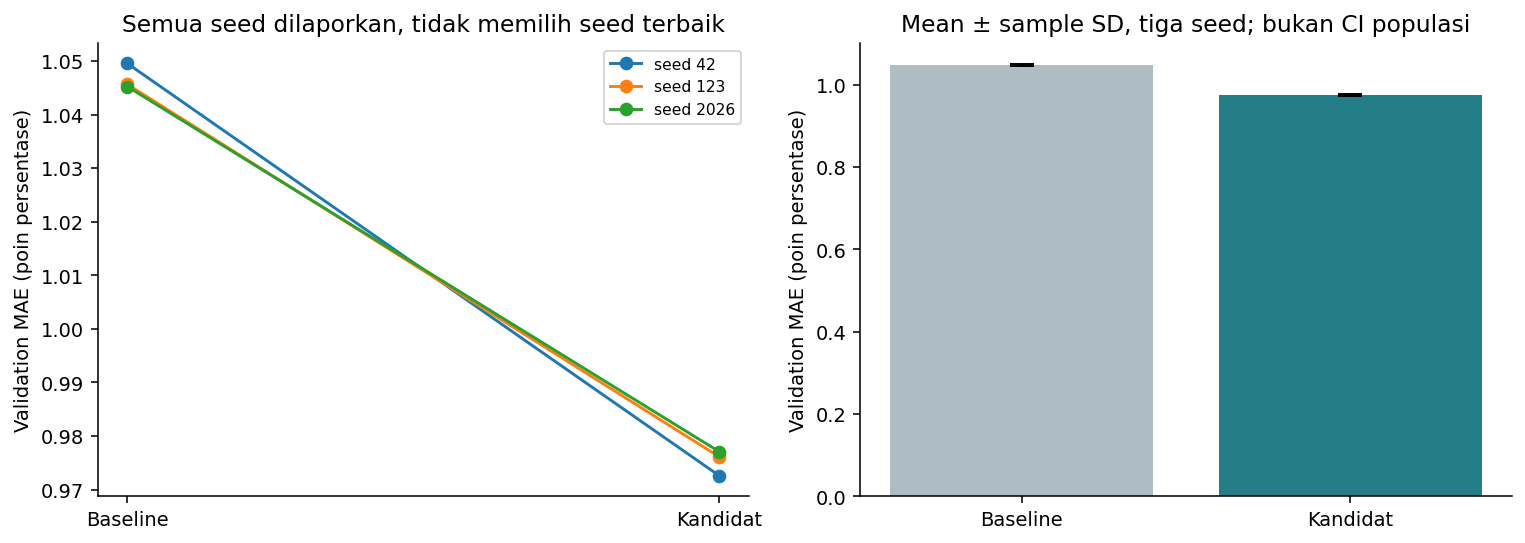

In [10]:
display(tables['seed_confirmation'])
display(tables['seed_summary'])
show('05_seed_confirmation.png')
assert tables['seed_confirmation'].groupby('group').seed.nunique().eq(3).all()
for group,rows in tables['seed_confirmation'].groupby('group'):
    reference=tables['seed_summary'].set_index('group').loc[group]
    assert np.isclose(reference.validation_mae_mean,rows.validation_mae_pp.mean())
    assert np.isclose(reference.validation_mae_std,rows.validation_mae_pp.std(ddof=1))

**Temuan:** rata-rata MAE validation baseline sekitar **1,0468 ± 0,0024**, kandidat **0,9752 ± 0,0024** poin SOH. Kandidat lebih rendah pada ketiga seed yang diuji.

SD adalah variasi training tiga seed pada split yang sama, bukan confidence interval populasi baterai. Validation juga dipakai berulang untuk memilih konfigurasi, sehingga nilai ini dapat optimistis. Test independen pada notebook 04 masih diperlukan setelah semua eksperimen selesai.

## 10. Error validation: kondisi mana yang lebih sulit?

MAE/RMSE/R² dihitung setelah inverse target scaling. Prediksi tidak dipotong ke rentang 0..100 demi memperbaiki skor. Lihat residual serta error per rentang SOH bersama jumlah observasi dan baterai.

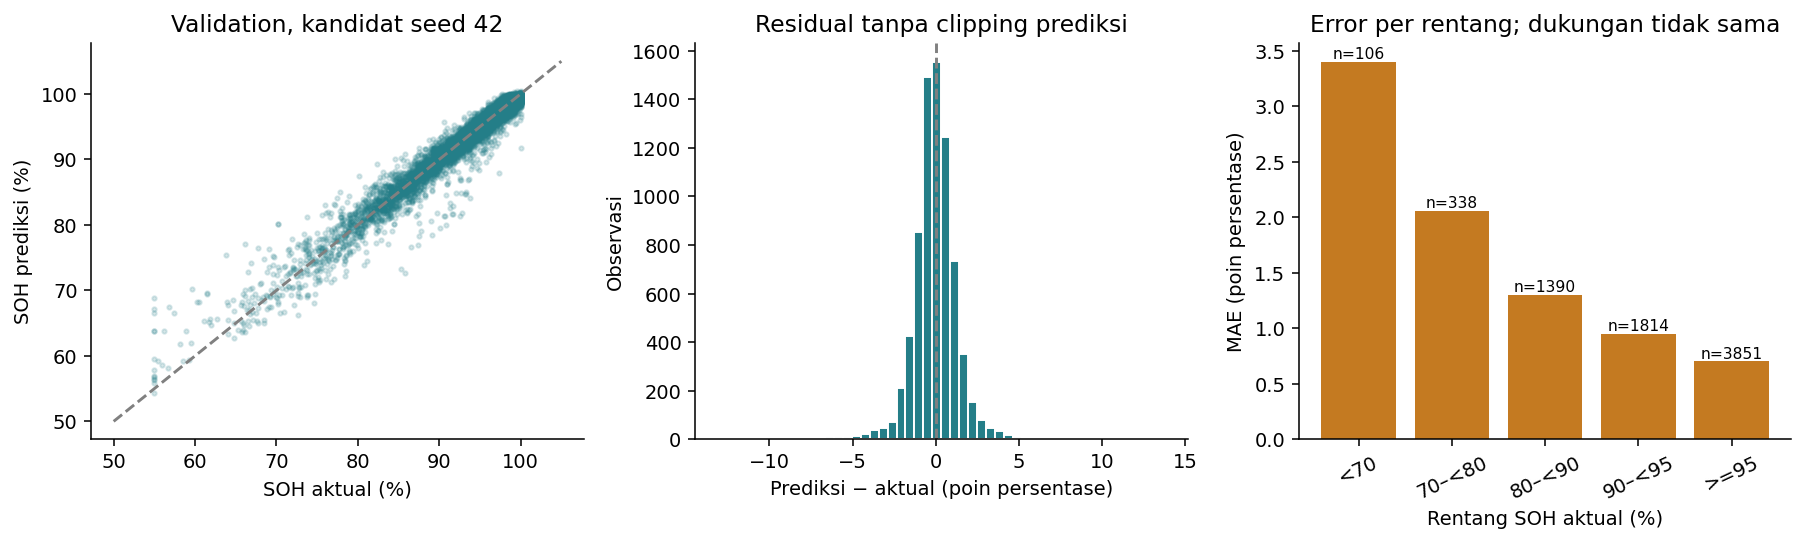

,soh_band,rows,batteries,mae_pp
0,<70,106,28,3.39998
1,70–<80,338,80,2.05669
2,80–<90,1390,218,1.29802
3,90–<95,1814,305,0.95186
4,>=95,3851,384,0.70290


MAE per observasi kandidat: 0.9725777586841967
Rerata MAE per baterai: 0.9765435831378673
Prediksi di luar 0..100 (%): 0.4133884517935725


In [11]:
show('06_validation_errors.png')
display(tables['candidate_validation_bands'])
print('MAE per observasi kandidat:',candidate['validation']['mae'])
print('Rerata MAE per baterai:',candidate['validation']['battery_mean_mae'])
print('Prediksi di luar 0..100 (%):',candidate['validation']['outside_0_100_pct'])
assert tables['candidate_validation_bands'].rows.sum()==7499

**Temuan penting:** SOH <70% memiliki MAE sekitar **3,40 poin** pada 106 observasi / 28 baterai, sedangkan SOH ≥95% sekitar **0,70 poin**. Skor keseluruhan tidak berarti kondisi baterai buruk sudah diprediksi sebaik kondisi sehat.

Ini bahan untuk eksperimen lanjutan, misalnya feature engineering atau loss/weighting yang dirancang di train, tanpa mengubah distribusi test atau mengklaim efek kausal. Tahap ini tidak menambahkan eksperimen tersebut secara diam-diam.

## 11. Kontrol kewajaran dan diagnosis overfitting/underfitting

Konstanta median/rerata **train** dipakai sebagai pemeriksaan sederhana, bukan model ML lain yang dilatih. Tujuannya memastikan MLP memberi manfaat dibanding hanya menebak pusat distribusi target.

In [12]:
display(tables['constant_references'])
gaps=[]
for label,run in [('baseline',baseline),('candidate',candidate)]:
    gaps.append({'model':label,'train_mae_pp':run['train']['mae'],'validation_mae_pp':run['validation']['mae'],
                 'validation_minus_train_pp':run['validation']['mae']-run['train']['mae']})
display(pd.DataFrame(gaps))

,reference,constant_soh,mae,rmse,r2,bias_pp,outside_0_100_pct,battery_mean_mae
0,train_median,95.23000,4.94317,7.36227,-0.10001,2.21991,0.0,4.93628
1,train_mean,92.91875,5.26972,7.02021,-0.00017,-0.09134,0.0,5.27368


,model,train_mae_pp,validation_mae_pp,validation_minus_train_pp
0,baseline,0.88613,1.04954,0.16340
1,candidate,0.92277,0.97258,0.04981


**Interpretasi:** model belajar lebih baik daripada konstanta train, tetapi tidak berarti bebas overfitting. Train–validation gap baseline sekitar 0,163 poin dan kandidat 0,050 poin pada checkpoint terpilih. Baca angka ini bersama learning curves dan hasil seed.

Tidak ada ambang gap universal atau target “accuracy 95%” untuk regresi. Underfitting perlu dilihat dari kemampuan mencapai train error yang memadai serta keterbatasan kapasitas/optimasi; kecilnya gap sendiri tidak membuktikan model sehat. Data sintetis dan kelemahan di rentang SOH rendah tetap menjadi batas utama.

## 12. Rekap semua run dan artefak

Setiap run mempunyai config.json, history.csv, summary.json, status.json, serta checkpoint lokal best/last. Prediksi validation per baris disimpan lokal; agregat dibagikan lewat Git. Run fixed-epoch diberi peran diagnostik agar tidak tertukar dengan model yang terpilih.

Tabel seluruh run dapat mencakup best checkpoint trajectory diagnostik; jangan langsung mengambil nilai terkecil seluruh tabel sebagai kandidat tanpa mengikuti protokol.

In [13]:
review = runs.copy()
review['purpose']=np.where(review.run_id.eq(study['fixed_epoch_run_id']),'fixed-epoch diagnostic; excluded from selection','search / seed confirmation')
display(review[['run_id','purpose','recipe','hidden_layers','activation','loss','seed','weight_decay','dropout','epochs_actual','best_epoch','validation_mae','validation_rmse','validation_r2']])
assert all((ROOT/run['checkpoint_best']).is_file() and (ROOT/run['checkpoint_last']).is_file() for run in summaries.values())
print('Checkpoint lokal tersedia untuk seluruh run unik.')

,run_id,purpose,recipe,hidden_layers,activation,loss,seed,weight_decay,dropout,epochs_actual,best_epoch,validation_mae,validation_rmse,validation_r2
0,run_83aa5197bac6,search / seed confirmation,baseline_standard,64-32,relu,mse,42,0.0000,0.0,37,22,1.04954,1.53503,0.95218
1,run_710346c78efb,search / seed confirmation,log_sensor_caps,64-32,relu,mse,42,0.0000,0.0,40,25,1.04512,1.55695,0.95080
2,run_c10d3e442614,search / seed confirmation,compact_log_sensor_caps,64-32,relu,mse,42,0.0000,0.0,37,36,1.07253,1.60706,0.94759
3,run_f76968c3adcb,search / seed confirmation,log_sensor_caps,32,relu,mse,42,0.0000,0.0,47,34,1.03938,1.54006,0.95187
4,run_7e756de0e2ab,search / seed confirmation,log_sensor_caps,64,relu,mse,42,0.0000,0.0,67,52,1.04232,1.52781,0.95263
5,run_0ec862f4da27,search / seed confirmation,log_sensor_caps,128-64-32,relu,mse,42,0.0000,0.0,38,23,1.06409,1.59138,0.94861
6,run_561c2914606b,search / seed confirmation,log_sensor_caps,32,tanh,mse,42,0.0000,0.0,49,34,1.03011,1.53969,0.95189
7,run_6ad052ad28d7,search / seed confirmation,log_sensor_caps,32,sigmoid,mse,42,0.0000,0.0,89,74,0.99199,1.49665,0.95454
8,run_001bb572bf8f,search / seed confirmation,log_sensor_caps,32,sigmoid,mae,42,0.0000,0.0,122,111,0.97518,1.49251,0.95479
9,run_e8f06bf33652,search / seed confirmation,log_sensor_caps,32,sigmoid,huber,42,0.0000,0.0,99,84,0.98834,1.48655,0.95515


Checkpoint lokal tersedia untuk seluruh run unik.


## 13. Pemeriksaan implementasi dan konsistensi hasil

Test perilaku memeriksa chain rule manual, jumlah parameter, shape batch satu, mode eval/dropout, metrik, larangan akses test oleh loader, checkpoint epoch minimum, reload prediksi, dan reuse cache. Test preprocessing sebelumnya juga tetap dijalankan. Data kecil buatan hanya untuk test, bukan eksperimen dataset.

In [14]:
checked = subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],cwd=ROOT,capture_output=True,text=True)
print(checked.stdout+checked.stderr)
assert checked.returncode==0

START run_39e7454aa5e6 probe hidden=[4] relu/mse seed=8
DONE run_39e7454aa5e6: best epoch=4/4, val MAE=7.0634, train MAE=7.0634, seconds=0.1
test_backprop_matches_manual_chain_rule_and_sgd_update (test_mlp_experiments.MLPTests.test_backprop_matches_manual_chain_rule_and_sgd_update) ... ok
test_checkpoint_is_best_validation_epoch_and_reloads_exactly (test_mlp_experiments.MLPTests.test_checkpoint_is_best_validation_epoch_and_reloads_exactly) ... ok
test_dropout_is_disabled_during_prediction (test_mlp_experiments.MLPTests.test_dropout_is_disabled_during_prediction) ... ok
test_metrics_and_battery_weighting (test_mlp_experiments.MLPTests.test_metrics_and_battery_weighting) ... ok
test_parameter_count_and_batch_one_shape (test_mlp_experiments.MLPTests.test_parameter_count_and_batch_one_shape) ... ok
test_supported_activations_losses_and_invalid_options (test_mlp_experiments.MLPTests.test_supported_activations_losses_and_invalid_options) ... ok
test_training_loader_never_requests_test_split 

In [15]:
assert study['source_sha256']==hashlib.sha256((ROOT/'src/mlp_experiments.py').read_bytes()).hexdigest()
assert study['settings_sha256']==hashlib.sha256((ROOT/'configs/mlp_study.json').read_bytes()).hexdigest()
assert study['test_loaded'] is False
for run_id,run in summaries.items():
    history=histories[run_id]
    assert history.epoch.tolist()==list(range(run['epochs_actual']+1))
    trained=history.loc[history.epoch.gt(0)]
    assert run['best_epoch']==int(trained.loc[trained.validation_mae_pp.idxmin(),'epoch'])
    assert np.isclose(trained.validation_mae_pp.min(),run['validation']['mae'])
    assert run['optimizer_updates']==int(np.ceil(34929/run['config']['batch_size']))*run['epochs_actual']
    assert run['first_update']['first_layer_max_weight_change']>0
assert len(report['figures'])==6
assert all((output/name).is_file() for name in report['figures'])
print('PASS: semua run/history/checkpoint konsisten; seluruh training memakai backpropagation; test tetap tidak dimuat.')
display(pd.Series(study['packages'],name='versi').to_frame())

PASS: semua run/history/checkpoint konsisten; seluruh training memakai backpropagation; test tetap tidak dimuat.


,versi
torch,2.11.0
numpy,2.2.5
pandas,2.3.2
scikit-learn,1.7.2


## 14. Reproduksi dan batas tahap berikutnya

```powershell
python -m src.mlp_experiments
python -m src.experiment_reporting
python scripts/run_notebook.py notebooks/03_mlp_experiments.ipynb --timeout 3600
python scripts/export_eda.py --stage experiments
```

Notebook juga dapat menjalankan study/report langsung; perintah modul terpisah tidak wajib. Timeout panjang hanya untuk sel training saat cache/checkpoint belum tersedia. Torch dipin 2.11.0; determinisme dikonfigurasi pada CPU ini, tetapi angka lintas hardware/versi tidak dijamin persis sama.

Artefak utama:
- `results/experiments/EXPERIMENT_REPORT.md` dan `EXPERIMENT_READING.html`.
- `run_summary.csv`, `stage_comparisons.csv`, `epoch_budget_comparison.csv`, `seed_confirmation.csv`.
- `study.json` untuk kandidat sementara/provenance.
- `models/mlp/<run_id>/best.pt`, `last.pt`, dan checkpoint endpoint tertentu, disimpan lokal.

Kandidat masih berdasarkan validation. Feature engineering domain dapat diuji berikutnya menggunakan baseline yang kini sudah terukur. Setelah seluruh keputusan dikunci, notebook 04 baru mengevaluasi test pada baseline/kandidat dan semua seed final. Tidak ada klaim performa test atau baterai nyata dalam notebook 03.

Referensi: [PyTorch backward/optimasi](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html), [saving/loading state_dict](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html), [reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html). Halaman stable dapat menunjukkan versi lebih baru; versi runtime tetap tercatat di study.json dan requirements.txt.